#Cell 1 – Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
import sqlite3

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


#Cell 2 – Upload and load the dataset

In [2]:
uploaded = files.upload()

file_name = list(uploaded.keys())[0]

df = pd.read_excel(file_name)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Saving Swiggy_dataset.xlsx to Swiggy_dataset (1).xlsx
Dataset loaded successfully!
Dataset Shape: (8680, 10)


,ID,Area,City,Restaurant,Price,Avg ratings,Total ratings,Food type,Address,Delivery time
0,211,Koramangala,Bangalore,Tandoor Hut,300,4.4,100,"Biryani,Chinese,North Indian,South Indian",5Th Block,59
1,221,Koramangala,Bangalore,Tunday Kababi,300,4.1,100,"Mughlai,Lucknowi",5Th Block,56
2,246,Jogupalya,Bangalore,Kim Lee,650,4.4,100,Chinese,Double Road,50
3,248,Indiranagar,Bangalore,New Punjabi Hotel,250,3.9,500,"North Indian,Punjabi,Tandoor,Chinese",80 Feet Road,57
4,249,Indiranagar,Bangalore,Nh8,350,4.0,50,"Rajasthani,Gujarati,North Indian,Snacks,Desser...",80 Feet Road,63


#Cell 3 – Understand the dataset

In [3]:
# Display first five rows
display(df.head())

# Display last five rows
display(df.tail())

# Dataset dimensions
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

# Column names
print("\nColumn Names:")
print(df.columns.tolist())

# Data types
print("\nData Types:")
print(df.dtypes)

# Dataset information
print("\nDataset Information:")
df.info()

,ID,Area,City,Restaurant,Price,Avg ratings,Total ratings,Food type,Address,Delivery time
0,211,Koramangala,Bangalore,Tandoor Hut,300,4.4,100,"Biryani,Chinese,North Indian,South Indian",5Th Block,59
1,221,Koramangala,Bangalore,Tunday Kababi,300,4.1,100,"Mughlai,Lucknowi",5Th Block,56
2,246,Jogupalya,Bangalore,Kim Lee,650,4.4,100,Chinese,Double Road,50
3,248,Indiranagar,Bangalore,New Punjabi Hotel,250,3.9,500,"North Indian,Punjabi,Tandoor,Chinese",80 Feet Road,57
4,249,Indiranagar,Bangalore,Nh8,350,4.0,50,"Rajasthani,Gujarati,North Indian,Snacks,Desser...",80 Feet Road,63


,ID,Area,City,Restaurant,Price,Avg ratings,Total ratings,Food type,Address,Delivery time
8675,464626,Panjarapole Cross Road,Ahmedabad,Malt Pizza,500,2.9,80,Pizzas,Navrangpura,40
8676,465835,Rohini,Delhi,Jay Mata Ji Home Kitchen,200,2.9,80,South Indian,Rohini,28
8677,465872,Rohini,Delhi,Chinese Kitchen King,150,2.9,80,"Chinese,Snacks,Tandoor",Rohini,58
8678,465990,Rohini,Delhi,Shree Ram Paratha Wala,150,2.9,80,"North Indian,Indian,Snacks",Rohini,28
8679,466488,Navrangpura,Ahmedabad,Sassy Street,250,2.9,80,"Chaat,Snacks,Chinese",Navrangpura,44


Number of Rows: 8680
Number of Columns: 10

Column Names:
['ID', 'Area', 'City', 'Restaurant', 'Price', 'Avg ratings', 'Total ratings', 'Food type', 'Address', 'Delivery time']

Data Types:
ID                 int64
Area              object
City              object
Restaurant        object
Price              int64
Avg ratings      float64
Total ratings      int64
Food type         object
Address           object
Delivery time      int64
dtype: object

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8680 entries, 0 to 8679
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   ID             8680 non-null   int64  
 1   Area           8680 non-null   object 
 2   City           8680 non-null   object 
 3   Restaurant     8680 non-null   object 
 4   Price          8680 non-null   int64  
 5   Avg ratings    8680 non-null   float64
 6   Total ratings  8680 non-null   int64  
 7   Food type      8

#Cell 4 – Check missing values and duplicates


In [4]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Total missing values
print("\nTotal Missing Values:", df.isnull().sum().sum())

# Check duplicate records
print("\nDuplicate Rows:", df.duplicated().sum())

# Remove duplicate records, if any
df = df.drop_duplicates().copy()

# Handle missing values
for col in df.select_dtypes(include=np.number).columns:
    df[col] = df[col].fillna(df[col].median())

for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].fillna(df[col].mode()[0])

print("\nMissing values after cleaning:")
print(df.isnull().sum().sum())

print("\nFinal Dataset Shape:", df.shape)

Missing Values:
ID               0
Area             0
City             0
Restaurant       0
Price            0
Avg ratings      0
Total ratings    0
Food type        0
Address          0
Delivery time    0
dtype: int64

Total Missing Values: 0

Duplicate Rows: 0

Missing values after cleaning:
0

Final Dataset Shape: (8680, 10)


#Cell 5 – Descriptive statistics

In [5]:
# Descriptive statistics for numerical variables
numerical_stats = df.describe().T

numerical_stats["Median"] = df.select_dtypes(
    include=np.number
).median()

numerical_stats = numerical_stats[
    ["count", "mean", "Median", "std", "min", "25%", "50%", "75%", "max"]
]

display(numerical_stats.round(2))

,count,mean,Median,std,min,25%,50%,75%,max
ID,8680.0,244812.07,283442.0,158671.62,211.0,72664.0,283442.0,393425.25,466928.0
Price,8680.0,348.44,300.0,230.94,0.0,200.0,300.0,400.00,2500.0
Avg ratings,8680.0,3.66,3.9,0.65,2.0,2.9,3.9,4.20,5.0
Total ratings,8680.0,156.63,80.0,391.45,20.0,50.0,80.0,100.00,10000.0
Delivery time,8680.0,53.97,53.0,14.29,20.0,44.0,53.0,64.00,109.0


#Categorical variable analysis

In [6]:
categorical_columns = df.select_dtypes(include="object").columns

for col in categorical_columns:
    print("\nVariable:", col)
    print("Unique Values:", df[col].nunique())
    print("Most Common Value:", df[col].mode()[0])
    print("\nTop 10 Categories:")
    display(df[col].value_counts().head(10))


Variable: Area
Unique Values: 829
Most Common Value: Rohini

Top 10 Categories:


,count
Area,
Rohini,257
Chembur,208
Kothrud,149
Andheri East,135
Navrangpura,132
Indiranagar,130
Kurla,129
Koramangala,124
Bidhannagar,123



Variable: City
Unique Values: 9
Most Common Value: Kolkata

Top 10 Categories:


,count
City,
Kolkata,1346
Mumbai,1277
Chennai,1106
Pune,1090
Hyderabad,1075
Bangalore,946
Ahmedabad,717
Delhi,611
Surat,512



Variable: Restaurant
Unique Values: 7863
Most Common Value: La Pino'Z Pizza

Top 10 Categories:


,count
Restaurant,
La Pino'Z Pizza,13
Nic Natural Ice Creams,10
Baskin Robbins,10
Subway,10
Behrouz Biryani,9
Kfc,9
Natural Ice Cream,9
Oven Story Pizza,9
Keventers - Milkshakes And Desserts,9



Variable: Food type
Unique Values: 3734
Most Common Value: Indian

Top 10 Categories:


,count
Food type,
Indian,389
Chinese,277
North Indian,246
Fast Food,240
South Indian,228
Desserts,106
"Indian,Chinese",106
"North Indian,Chinese",99
Bakery,90



Variable: Address
Unique Values: 2334
Most Common Value: Rohini

Top 10 Categories:


,count
Address,
Rohini,229
Chembur,166
Kothrud,158
Kurla,138
Navrangpura,136
Scruz Bandra East,126
Salt Lake,120
Marol Sakinaka,116
Central Bangalore,116


#Cell 6 – Outlier detection using IQR

In [7]:
numeric_columns = df.select_dtypes(include=np.number).columns

outlier_results = []

for col in numeric_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_limit) |
        (df[col] > upper_limit)
    ]

    outlier_results.append({
        "Variable": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Limit": lower_limit,
        "Upper Limit": upper_limit,
        "Outlier Count": len(outliers)
    })

outlier_table = pd.DataFrame(outlier_results)

display(outlier_table.round(2))

,Variable,Q1,Q3,IQR,Lower Limit,Upper Limit,Outlier Count
0,ID,72664.0,393425.25,320761.25,-408477.88,874567.12,0
1,Price,200.0,400.00,200.00,-100.00,700.00,583
2,Avg ratings,2.9,4.20,1.30,0.95,6.15,0
3,Total ratings,50.0,100.00,50.00,-25.00,175.00,995
4,Delivery time,44.0,64.00,20.00,14.00,94.00,22


#Cell 7 – Create a food category variable

In [8]:
top_food_types = df["Food type"].value_counts().head(10).index

df["Food_category"] = np.where(
    df["Food type"].isin(top_food_types),
    df["Food type"],
    "Other"
)

print("Food Categories:")
print(df["Food_category"].value_counts())

Food Categories:
Food_category
Other                   6817
Indian                   389
Chinese                  277
North Indian             246
Fast Food                240
South Indian             228
Desserts                 106
Indian,Chinese           106
North Indian,Chinese      99
Bakery                    90
Beverages                 82
Name: count, dtype: int64


#Cell 8 – Visualisation 1: Delivery time distribution

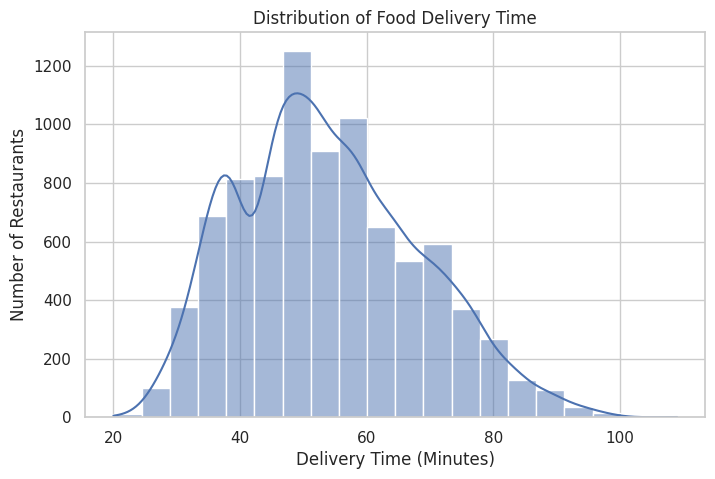

In [9]:
plt.figure(figsize=(8,5))

sns.histplot(
    df["Delivery time"],
    bins=20,
    kde=True
)

plt.title("Distribution of Food Delivery Time")
plt.xlabel("Delivery Time (Minutes)")
plt.ylabel("Number of Restaurants")

plt.show()

#Cell 9 – Visualisation 2: Delivery time boxplot

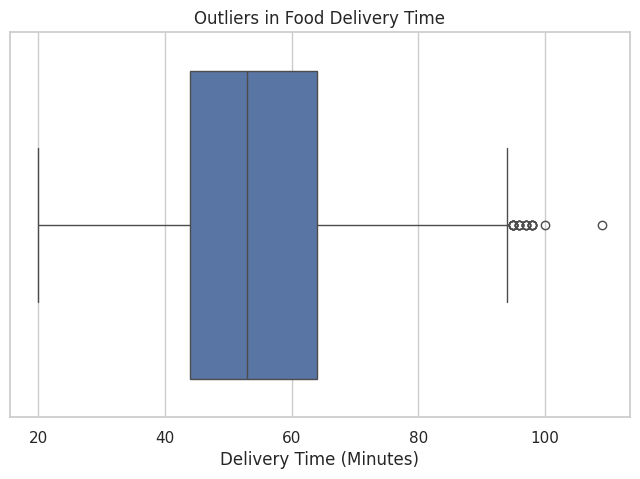

In [10]:
plt.figure(figsize=(8,5))

sns.boxplot(x=df["Delivery time"])

plt.title("Outliers in Food Delivery Time")
plt.xlabel("Delivery Time (Minutes)")

plt.show()

#Cell 10 – Visualisation 3: Price distribution

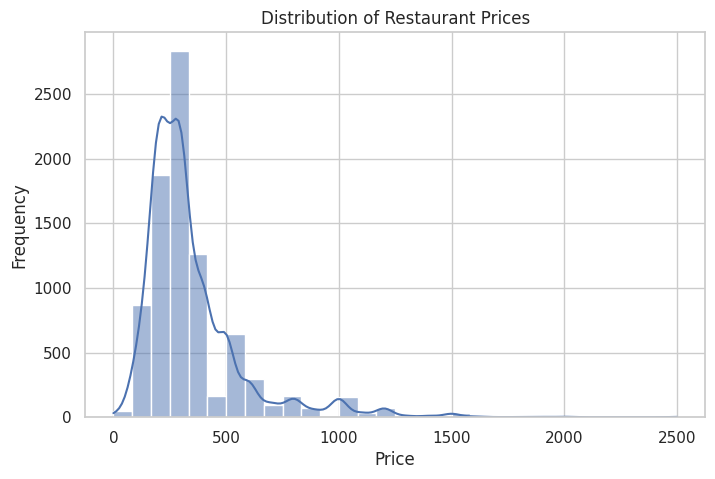

In [11]:
plt.figure(figsize=(8,5))

sns.histplot(df["Price"], bins=30, kde=True)

plt.title("Distribution of Restaurant Prices")
plt.xlabel("Price")
plt.ylabel("Frequency")

plt.show()

#Cell 11 – Visualisation 4: Average ratings distribution

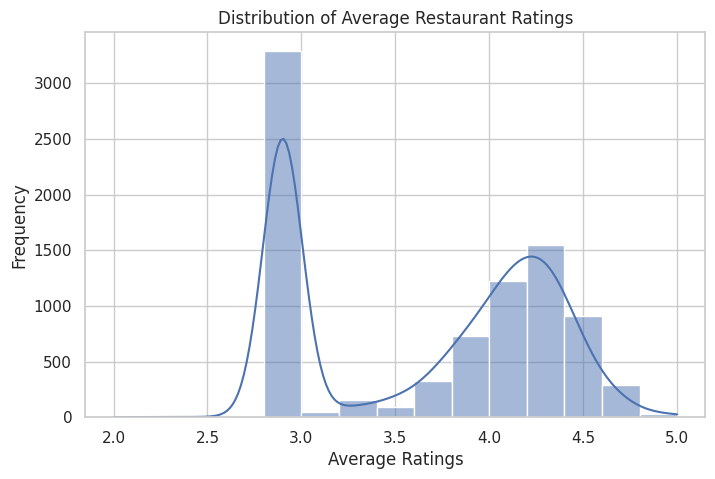

In [12]:
plt.figure(figsize=(8,5))

sns.histplot(df["Avg ratings"], bins=15, kde=True)

plt.title("Distribution of Average Restaurant Ratings")
plt.xlabel("Average Ratings")
plt.ylabel("Frequency")

plt.show()

#Cell 12 – Visualisation 5: Restaurants by city

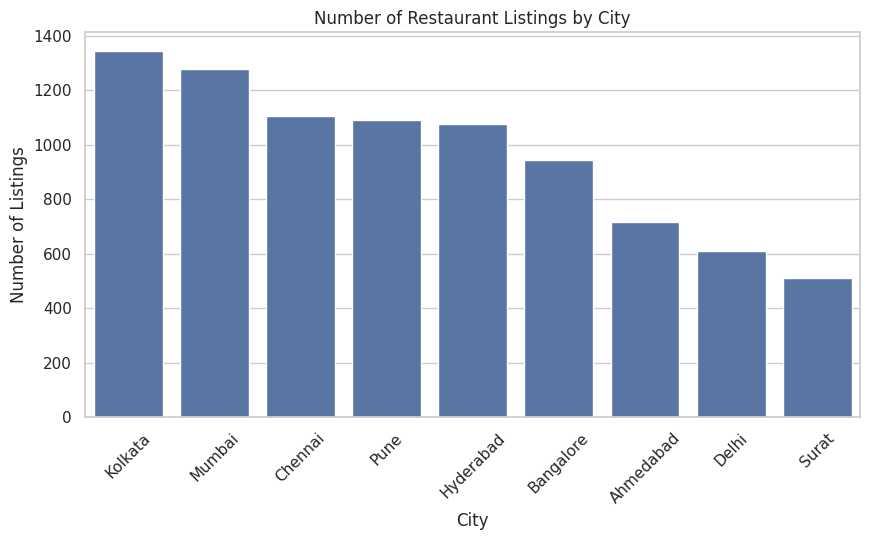

In [13]:
plt.figure(figsize=(10,5))

sns.countplot(
    data=df,
    x="City",
    order=df["City"].value_counts().index
)

plt.title("Number of Restaurant Listings by City")
plt.xlabel("City")
plt.ylabel("Number of Listings")

plt.xticks(rotation=45)
plt.show()

#Cell 13 – Visualisation 6: Average delivery time by city

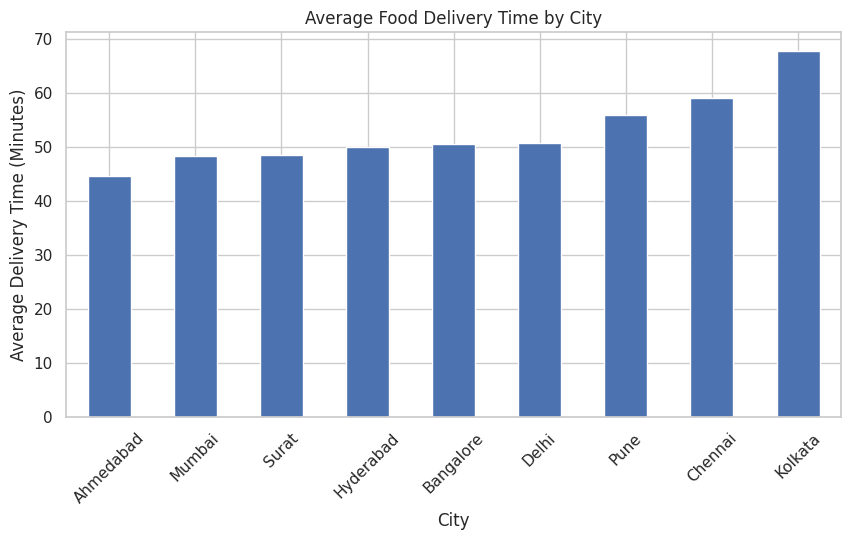

In [14]:
city_delivery = df.groupby("City")["Delivery time"].mean().sort_values()

plt.figure(figsize=(10,5))

city_delivery.plot(kind="bar")

plt.title("Average Food Delivery Time by City")
plt.xlabel("City")
plt.ylabel("Average Delivery Time (Minutes)")

plt.xticks(rotation=45)
plt.show()

#Cell 14 – Visualisation 7: Delivery time variation by city


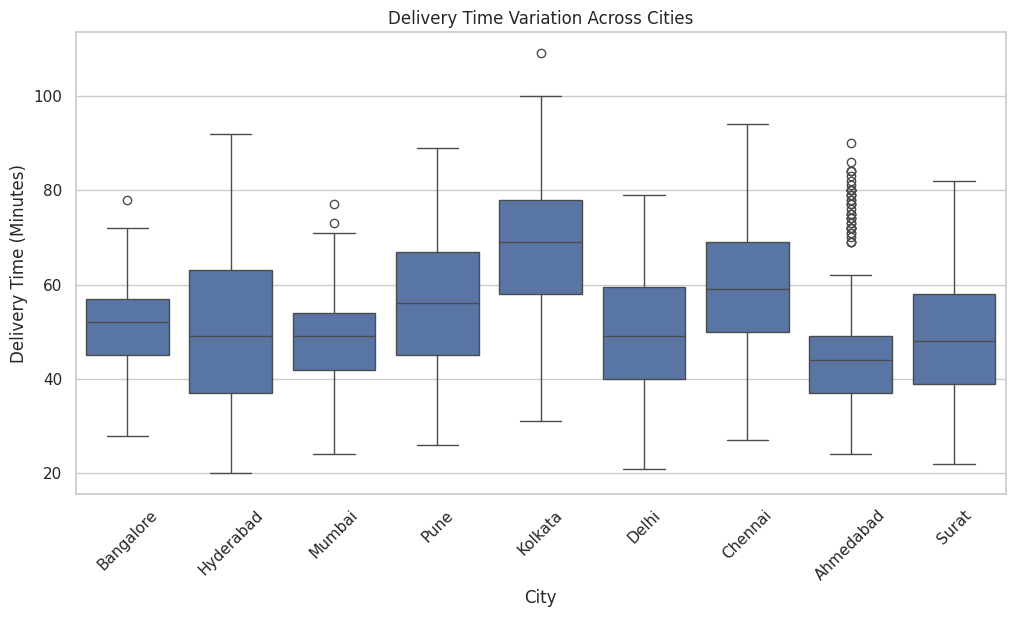

In [15]:
plt.figure(figsize=(12,6))

sns.boxplot(
    data=df,
    x="City",
    y="Delivery time"
)

plt.title("Delivery Time Variation Across Cities")
plt.xlabel("City")
plt.ylabel("Delivery Time (Minutes)")

plt.xticks(rotation=45)
plt.show()

#Cell 15 – Visualisation 8: Top food categories

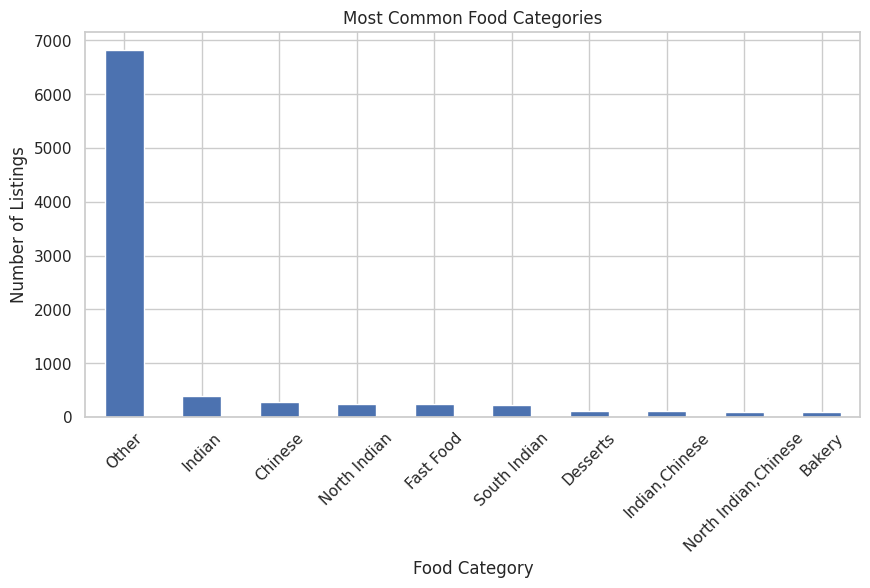

In [16]:
food_counts = df["Food_category"].value_counts().head(10)

plt.figure(figsize=(10,5))

food_counts.plot(kind="bar")

plt.title("Most Common Food Categories")
plt.xlabel("Food Category")
plt.ylabel("Number of Listings")

plt.xticks(rotation=45)
plt.show()

#Cell 16 – Visualisation 9: Price versus delivery time

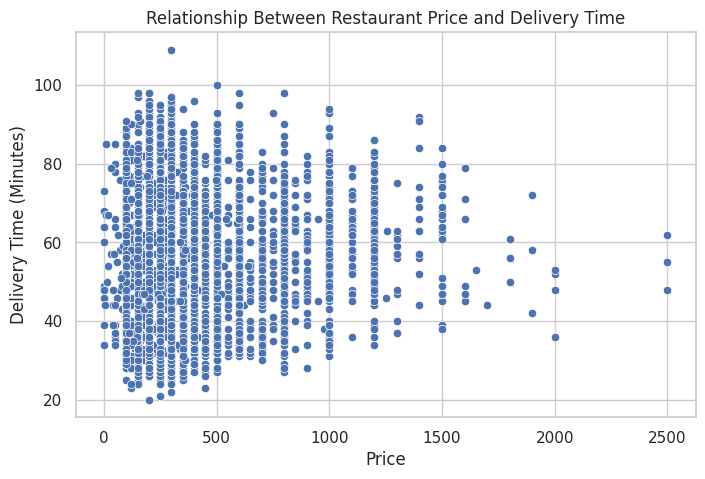

In [17]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x="Price",
    y="Delivery time"
)

plt.title("Relationship Between Restaurant Price and Delivery Time")
plt.xlabel("Price")
plt.ylabel("Delivery Time (Minutes)")

plt.show()

#Cell 17 – Visualisation 10: Ratings versus delivery time

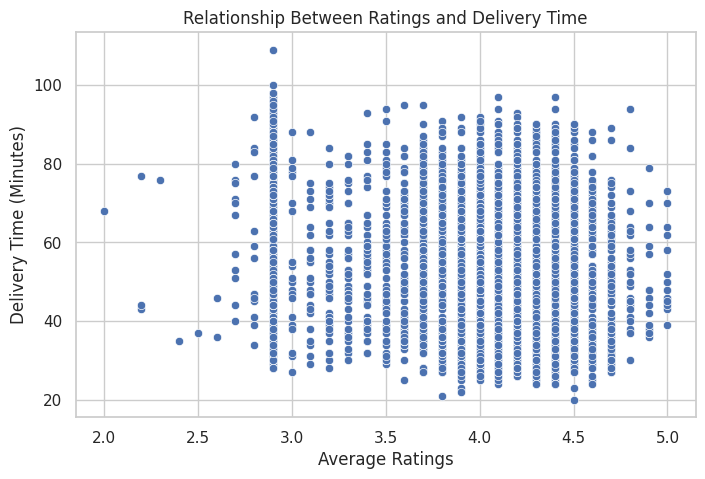

In [18]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x="Avg ratings",
    y="Delivery time"
)

plt.title("Relationship Between Ratings and Delivery Time")
plt.xlabel("Average Ratings")
plt.ylabel("Delivery Time (Minutes)")

plt.show()

#Cell 18 – Visualisation 11: Total ratings versus delivery time

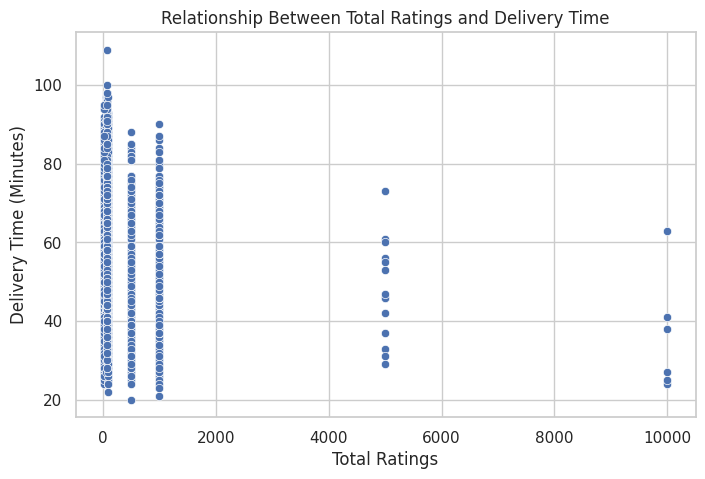

In [19]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x="Total ratings",
    y="Delivery time"
)

plt.title("Relationship Between Total Ratings and Delivery Time")
plt.xlabel("Total Ratings")
plt.ylabel("Delivery Time (Minutes)")

plt.show()

#Cell 19 – Visualisation 12: Correlation heatmap

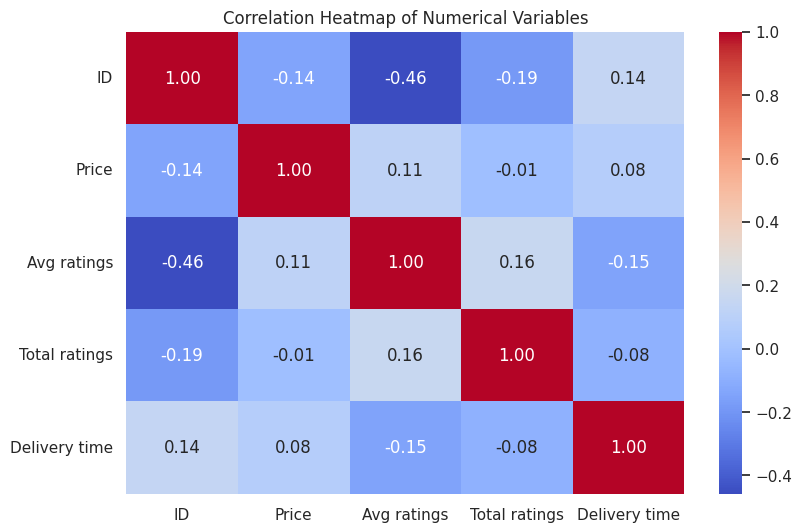

In [20]:
correlation = df.select_dtypes(include=np.number).corr()

plt.figure(figsize=(9,6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Numerical Variables")

plt.show()

#Part 2: Multiple Linear Regression
#Cell 20 – Prepare data for regression

In [21]:
# Create a copy for regression
model_df = df.copy()

# Log transformation to reduce the effect of highly skewed total ratings
model_df["log_total_ratings"] = np.log1p(
    model_df["Total ratings"]
)

# Select variables
model_df = model_df[
    [
        "Delivery time",
        "Price",
        "Avg ratings",
        "log_total_ratings",
        "City",
        "Food_category"
    ]
]

# Split into training and testing data
train_data, test_data = train_test_split(
    model_df,
    test_size=0.20,
    random_state=42
)

print("Training Data Shape:", train_data.shape)
print("Testing Data Shape:", test_data.shape)

Training Data Shape: (6944, 6)
Testing Data Shape: (1736, 6)


#Cell 21 – Model 1: Regression without interaction

In [22]:
model1 = smf.ols(
    formula="""
    Q('Delivery time') ~ Price
    + Q('Avg ratings')
    + log_total_ratings
    + C(City)
    + C(Food_category)
    """,
    data=train_data
).fit()

print(model1.summary())

                            OLS Regression Results                            
Dep. Variable:     Q('Delivery time')   R-squared:                       0.295
Model:                            OLS   Adj. R-squared:                  0.293
Method:                 Least Squares   F-statistic:                     138.0
Date:                Wed, 25 Nov 2026   Prob (F-statistic):               0.00
Time:                        15:14:45   Log-Likelihood:                -27087.
No. Observations:                6944   AIC:                         5.422e+04
Df Residuals:                    6922   BIC:                         5.437e+04
Df Model:                          21                                         
Covariance Type:            nonrobust                                         
                                               coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------

#Cell 22 – Model 2: Regression with interaction

In [23]:
model2 = smf.ols(
    formula="""
    Q('Delivery time') ~ Price
    + Q('Avg ratings')
    + log_total_ratings
    + C(City)
    + C(Food_category)
    + Price:Q('Avg ratings')
    """,
    data=train_data
).fit()

print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:     Q('Delivery time')   R-squared:                       0.296
Model:                            OLS   Adj. R-squared:                  0.293
Method:                 Least Squares   F-statistic:                     132.0
Date:                Wed, 25 Nov 2026   Prob (F-statistic):               0.00
Time:                        15:15:16   Log-Likelihood:                -27085.
No. Observations:                6944   AIC:                         5.422e+04
Df Residuals:                    6921   BIC:                         5.437e+04
Df Model:                          22                                         
Covariance Type:            nonrobust                                         
                                               coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------

#Cell 23 – Compare both regression models

In [24]:
# Predictions on test data
pred1 = model1.predict(test_data)
pred2 = model2.predict(test_data)

# Calculate model performance
comparison = pd.DataFrame({

    "Measure": [
        "R-squared",
        "Adjusted R-squared",
        "AIC",
        "BIC",
        "F-statistic",
        "F-statistic p-value",
        "Test MAE",
        "Test RMSE",
        "Test R-squared"
    ],

    "Model 1 - Without Interaction": [
        model1.rsquared,
        model1.rsquared_adj,
        model1.aic,
        model1.bic,
        model1.fvalue,
        model1.f_pvalue,
        mean_absolute_error(test_data["Delivery time"], pred1),
        np.sqrt(mean_squared_error(test_data["Delivery time"], pred1)),
        r2_score(test_data["Delivery time"], pred1)
    ],

    "Model 2 - With Interaction": [
        model2.rsquared,
        model2.rsquared_adj,
        model2.aic,
        model2.bic,
        model2.fvalue,
        model2.f_pvalue,
        mean_absolute_error(test_data["Delivery time"], pred2),
        np.sqrt(mean_squared_error(test_data["Delivery time"], pred2)),
        r2_score(test_data["Delivery time"], pred2)
    ]

})

display(comparison.round(4))

,Measure,Model 1 - Without Interaction,Model 2 - With Interaction
0,R-squared,0.2951,0.2956
1,Adjusted R-squared,0.2930,0.2934
2,AIC,54218.5201,54215.8091
3,BIC,54369.1240,54373.2587
4,F-statistic,138.0038,132.0148
5,F-statistic p-value,0.0000,0.0000
6,Test MAE,10.0182,10.0055
7,Test RMSE,12.1726,12.1560
8,Test R-squared,0.2911,0.2930


#Cell 24 – Compare significant predictors

In [25]:
print("MODEL 1 SIGNIFICANT PREDICTORS")

significant_model1 = model1.pvalues[
    model1.pvalues < 0.05
]

display(significant_model1)

print("\nMODEL 2 SIGNIFICANT PREDICTORS")

significant_model2 = model2.pvalues[
    model2.pvalues < 0.05
]

display(significant_model2)

MODEL 1 SIGNIFICANT PREDICTORS


,0
Intercept,1.602217e-247
C(City)[T.Bangalore],1.713269e-18
C(City)[T.Chennai],1.029444e-109
C(City)[T.Delhi],6.171326e-16
C(City)[T.Hyderabad],7.494362e-18
C(City)[T.Kolkata],2.110236e-277
C(City)[T.Mumbai],2.441864e-06
C(City)[T.Pune],9.092236e-59
C(City)[T.Surat],1.436475e-06
Price,2.808801e-14



MODEL 2 SIGNIFICANT PREDICTORS


,0
Intercept,2.401830e-186
C(City)[T.Bangalore],1.726340e-18
C(City)[T.Chennai],9.554373e-110
C(City)[T.Delhi],4.919748e-16
C(City)[T.Hyderabad],5.546195e-18
C(City)[T.Kolkata],1.049268e-277
C(City)[T.Mumbai],2.052526e-06
C(City)[T.Pune],7.314664e-59
C(City)[T.Surat],1.473224e-06
Q('Avg ratings'),2.334633e-29


#Cell 25 – Compare regression coefficients

In [26]:
coefficient_comparison = pd.DataFrame({

    "Model 1 Coefficients": model1.params,
    "Model 1 P-values": model1.pvalues,
    "Model 2 Coefficients": model2.params,
    "Model 2 P-values": model2.pvalues

})

display(coefficient_comparison.round(4))

,Model 1 Coefficients,Model 1 P-values,Model 2 Coefficients,Model 2 P-values
C(City)[T.Bangalore],5.8829,0.0000,5.8808,0.0000
C(City)[T.Chennai],14.7188,0.0000,14.7172,0.0000
C(City)[T.Delhi],5.9749,0.0000,5.9943,0.0000
C(City)[T.Hyderabad],5.6343,0.0000,5.6562,0.0000
C(City)[T.Kolkata],23.2459,0.0000,23.2543,0.0000
C(City)[T.Mumbai],2.9737,0.0000,2.9955,0.0000
C(City)[T.Pune],10.6043,0.0000,10.6105,0.0000
C(City)[T.Surat],3.7640,0.0000,3.7590,0.0000
C(Food_category)[T.Beverages],0.8947,0.6649,0.7995,0.6987
C(Food_category)[T.Chinese],-0.3094,0.8519,-0.4734,0.7753


#Cell 26 – Residual analysis

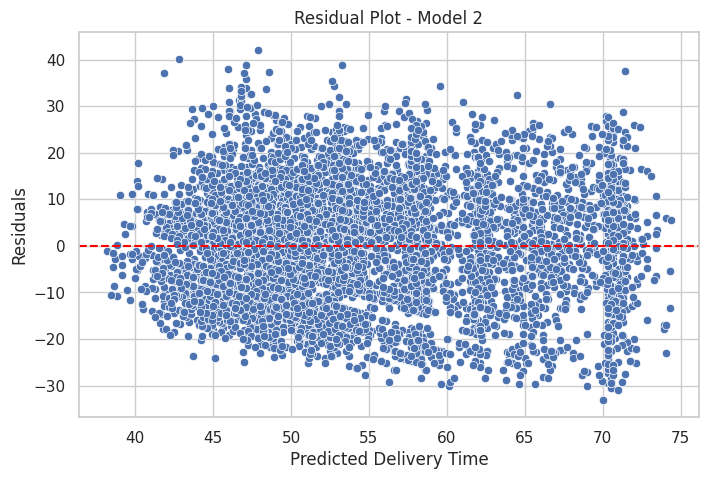

In [27]:
# Predictions using Model 2
predicted_values = model2.predict(train_data)

residuals = train_data["Delivery time"] - predicted_values

plt.figure(figsize=(8,5))

sns.scatterplot(
    x=predicted_values,
    y=residuals
)

plt.axhline(y=0, color="red", linestyle="--")

plt.title("Residual Plot - Model 2")
plt.xlabel("Predicted Delivery Time")
plt.ylabel("Residuals")

plt.show()

#Cell 27 – Actual versus predicted delivery time

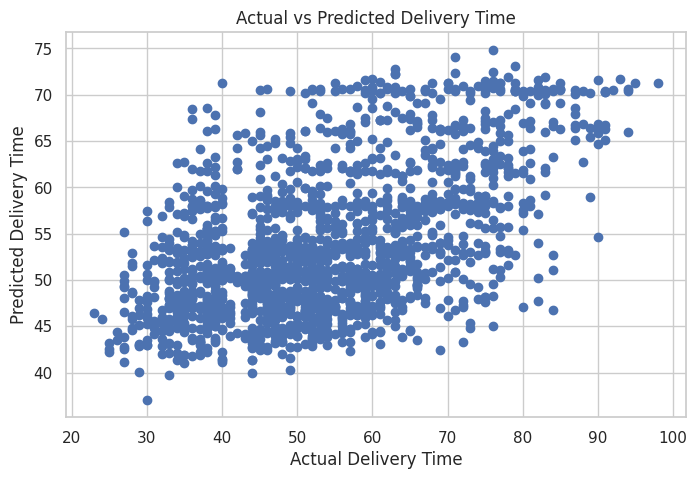

In [28]:
plt.figure(figsize=(8,5))

plt.scatter(
    test_data["Delivery time"],
    pred2
)

plt.xlabel("Actual Delivery Time")
plt.ylabel("Predicted Delivery Time")

plt.title("Actual vs Predicted Delivery Time")

plt.show()

#Cell 28 – Display the three highest and lowest average delivery-time cities

In [29]:
city_analysis = df.groupby("City").agg(

    Average_Delivery_Time=("Delivery time", "mean"),
    Total_Listings=("ID", "count"),
    Average_Price=("Price", "mean"),
    Average_Rating=("Avg ratings", "mean")

).reset_index()

city_analysis = city_analysis.sort_values(
    by="Average_Delivery_Time",
    ascending=False
)

display(city_analysis.round(2))

,City,Average_Delivery_Time,Total_Listings,Average_Price,Average_Rating
5,Kolkata,67.81,1346,362.29,3.70
2,Chennai,58.97,1106,356.25,3.78
7,Pune,55.85,1090,353.76,3.55
3,Delhi,50.73,611,333.30,3.53
1,Bangalore,50.53,946,382.52,3.76
4,Hyderabad,49.93,1075,299.93,3.70
8,Surat,48.48,512,270.17,3.58
6,Mumbai,48.32,1277,393.79,3.60
0,Ahmedabad,44.71,717,318.13,3.60
